# Customer Segmentation: RFM Analysis and K-Means Clustering

## Project Objective

This analysis aims to identify meaningful customer segments based on purchasing behaviour using Recency, Frequency and Monetary (RFM) metrics.

The analysis will apply K-Means clustering to group customers with similar purchasing patterns and develop actionable recommendations for customer retention, personalised marketing and revenue growth.

## Analysis Approach

1. Load and validate customer data.
2. Prepare RFM metrics.
3. Explore RFM distributions and outliers.
4. Scale customer features.
5. Determine an appropriate number of clusters.
6. Apply K-Means clustering.
7. Evaluate and interpret customer segments.
8. Develop business recommendations.

## 1. Load and Validate Customer Data

This section imports the required Python libraries, loads the cleaned customer intelligence dataset, and checks its structure before RFM analysis.

In [1]:
# STEP 26: Load customer intelligence dataset

import pandas as pd
import numpy as np
from pathlib import Path

# Locate the project root
project_root = Path.cwd().resolve()

if project_root.name == "jupyter_notebooks":
    project_root = project_root.parent

# Define dataset path
customer_path = (
    project_root
    / "data"
    / "tableau"
    / "retail_customer_intelligence.csv"
)

# Load customer data
customer_df = pd.read_csv(customer_path)

# Display basic dataset information
print("CUSTOMER DATASET VALIDATION")
print("-" * 45)

print(f"Dataset shape: {customer_df.shape}")

print("\nColumn names:")
print(customer_df.columns.tolist())

print("\nFirst five customers:")
display(customer_df.head())

CUSTOMER DATASET VALIDATION
---------------------------------------------
Dataset shape: (4337, 10)

Column names:
['CustomerID', 'TotalSpending', 'TotalOrders', 'TotalUnits', 'FirstPurchase', 'LastPurchase', 'PurchaseFrequency', 'AverageOrderValue', 'CustomerType', 'RecencyDays']

First five customers:


,CustomerID,TotalSpending,TotalOrders,TotalUnits,FirstPurchase,LastPurchase,PurchaseFrequency,AverageOrderValue,CustomerType,RecencyDays
0,12346,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.600000,One-Time Customer,326
1,12347,4310.00,7,2458,2010-12-07 14:57:00,2011-12-07 15:52:00,7,615.714286,Repeat Customer,3
2,12348,1797.24,4,2341,2010-12-16 19:09:00,2011-09-25 13:13:00,4,449.310000,Repeat Customer,76
3,12349,1757.55,1,631,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.550000,One-Time Customer,19
4,12350,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.400000,One-Time Customer,311


## 2. Prepare and Validate RFM Metrics

This section extracts Recency, Frequency and Monetary metrics from the cleaned customer dataset and checks for missing values, duplicate customers and invalid measurements.

In [2]:
# STEP 27: Prepare and validate RFM metrics

# Select customer identifiers and RFM variables
rfm_df = customer_df[
    ["CustomerID", "RecencyDays", "PurchaseFrequency", "TotalSpending"]
].copy()

# Rename columns for RFM analysis
rfm_df = rfm_df.rename(columns={
    "RecencyDays": "Recency",
    "PurchaseFrequency": "Frequency",
    "TotalSpending": "Monetary"
})

print("RFM DATA VALIDATION")
print("-" * 45)

print(f"Dataset shape: {rfm_df.shape}")

print("\nMissing values:")
print(rfm_df.isnull().sum())

print("\nDuplicate customer IDs:")
print(rfm_df["CustomerID"].duplicated().sum())

print("\nInvalid RFM values:")
print("Negative recency:", (rfm_df["Recency"] < 0).sum())
print("Zero or negative frequency:", (rfm_df["Frequency"] <= 0).sum())
print("Zero or negative monetary:", (rfm_df["Monetary"] <= 0).sum())

print("\nRFM descriptive statistics:")
display(rfm_df[["Recency", "Frequency", "Monetary"]].describe())

print("\nFirst five RFM records:")
display(rfm_df.head())

RFM DATA VALIDATION
---------------------------------------------
Dataset shape: (4337, 4)

Missing values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate customer IDs:
0

Invalid RFM values:
Negative recency: 0
Zero or negative frequency: 0
Zero or negative monetary: 0

RFM descriptive statistics:


,Recency,Frequency,Monetary
count,4337.000000,4337.000000,4337.000000
mean,93.075628,4.272539,2049.048237
std,100.018136,7.698808,8986.234964
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.460000
50%,51.000000,2.000000,668.580000
75%,143.000000,5.000000,1660.880000
max,374.000000,209.000000,280206.020000



First five RFM records:


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40


## 3. Explore RFM Distributions and Outliers

This section examines the distributions of Recency, Frequency
and Monetary values to identify skewness and extreme observations
that may influence K-Means clustering.

In [3]:
# STEP 28: Examine RFM distributions and skewness

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualisation style
sns.set_theme(style="whitegrid")

# Define RFM variables
rfm_features = ["Recency", "Frequency", "Monetary"]

# Create distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(rfm_features):
    sns.histplot(
        rfm_df[feature],
        bins=40,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} Distribution")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Calculate skewness
print("RFM DISTRIBUTION SKEWNESS")
print("-" * 45)

for feature in rfm_features:
    print(f"{feature}: {rfm_df[feature].skew():.2f}")

<Figure size 1800x500 with 3 Axes>

RFM DISTRIBUTION SKEWNESS
---------------------------------------------
Recency: 1.25
Frequency: 12.07
Monetary: 19.34


## 4. Identify RFM Outliers

The Interquartile Range (IQR) method is used to identify
potential outliers in Recency, Frequency and Monetary values.

Outliers will be investigated before any transformation
or exclusion decisions are made, as high-value customers
may represent commercially important customer segments.

In [4]:
# STEP 29: Identify RFM outliers using the IQR method

print("RFM OUTLIER ANALYSIS")
print("-" * 50)

for feature in ["Recency", "Frequency", "Monetary"]:

    q1 = rfm_df[feature].quantile(0.25)
    q3 = rfm_df[feature].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (rfm_df[feature] < lower_bound) |
        (rfm_df[feature] > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(rfm_df)
    ) * 100

    print(f"\n{feature.upper()}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower boundary: {lower_bound:.2f}")
    print(f"Upper boundary: {upper_bound:.2f}")
    print(f"Potential outliers: {outlier_count:,}")
    print(f"Outlier percentage: {outlier_percentage:.2f}%")

RFM OUTLIER ANALYSIS
--------------------------------------------------

RECENCY
IQR: 125.00
Lower boundary: -169.50
Upper boundary: 330.50
Potential outliers: 152
Outlier percentage: 3.50%

FREQUENCY
IQR: 4.00
Lower boundary: -5.00
Upper boundary: 11.00
Potential outliers: 285
Outlier percentage: 6.57%

MONETARY
IQR: 1354.42
Lower boundary: -1725.17
Upper boundary: 3692.51
Potential outliers: 424
Outlier percentage: 9.78%


## 5. Transform RFM Features

Due to substantial positive skewness and extreme observations,
a logarithmic transformation is applied to Recency, Frequency
and Monetary values.

The transformation reduces the influence of extreme values
while retaining all customers for segmentation.

The transformed variables will subsequently be scaled
before K-Means clustering.

In [5]:
# STEP 30: Apply logarithmic transformation to RFM features

# Create a copy to preserve original RFM values
rfm_transformed = rfm_df.copy()

# Apply log1p transformation
rfm_features = ["Recency", "Frequency", "Monetary"]

for feature in rfm_features:
    rfm_transformed[feature] = np.log1p(
        rfm_transformed[feature]
    )

print("RFM LOG TRANSFORMATION")
print("-" * 50)

print("\nSkewness before transformation:")
print(rfm_df[rfm_features].skew().round(2))

print("\nSkewness after transformation:")
print(rfm_transformed[rfm_features].skew().round(2))

print("\nFirst five transformed records:")
display(rfm_transformed.head())

RFM LOG TRANSFORMATION
--------------------------------------------------

Skewness before transformation:
Recency       1.25
Frequency    12.07
Monetary     19.34
dtype: float64

Skewness after transformation:
Recency     -0.33
Frequency    1.21
Monetary     0.40
dtype: float64

First five transformed records:


,CustomerID,Recency,Frequency,Monetary
0,12346,5.789960,0.693147,11.253955
1,12347,1.386294,2.079442,8.368925
2,12348,4.343805,1.609438,7.494564
3,12349,2.995732,0.693147,7.472245
4,12350,5.743003,0.693147,5.815324


## 6. Standardise RFM Features

StandardScaler is applied to the log-transformed RFM features
to ensure that Recency, Frequency and Monetary contribute
comparably to distance calculations during K-Means clustering.

The original customer-level RFM values are preserved for
subsequent business interpretation.

In [6]:
# STEP 31: Standardise log-transformed RFM features

from sklearn.preprocessing import StandardScaler

# Select transformed RFM features
rfm_features = ["Recency", "Frequency", "Monetary"]

X = rfm_transformed[rfm_features].copy()

# Initialise the scaler
scaler = StandardScaler()

# Fit and transform the RFM features
X_scaled = scaler.fit_transform(X)

# Convert scaled values into a DataFrame
rfm_scaled = pd.DataFrame(
    X_scaled,
    columns=rfm_features,
    index=rfm_transformed.index
)

print("STANDARDISED RFM DATA VALIDATION")
print("-" * 50)

print(f"Dataset shape: {rfm_scaled.shape}")

print("\nFeature means:")
print(rfm_scaled.mean().round(4))

print("\nFeature standard deviations:")
print(rfm_scaled.std(ddof=0).round(4))

print("\nMissing values:")
print(rfm_scaled.isnull().sum())

print("\nFirst five standardised records:")
display(rfm_scaled.head())

STANDARDISED RFM DATA VALIDATION
--------------------------------------------------
Dataset shape: (4337, 3)

Feature means:
Recency     -0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64

Feature standard deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

First five standardised records:


,Recency,Frequency,Monetary
0,1.478640,-0.955202,3.707259
1,-1.890603,1.074234,1.414684
2,0.372188,0.386182,0.719877
3,-0.659223,-0.955202,0.702141
4,1.442713,-0.955202,-0.614523


## 7. Determine the Optimal Number of Clusters

The Elbow Method is used to evaluate K-Means clustering
solutions with different numbers of clusters.

Inertia measures the total squared distance between
customers and their assigned cluster centroids.

The analysis will also use Silhouette Scores to assess
cluster separation and cohesion before selecting the
final number of customer segments.

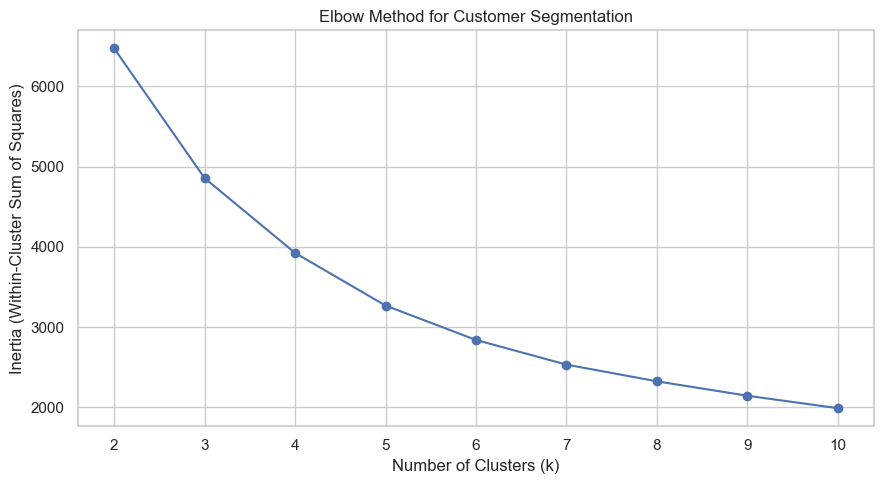

K-MEANS INERTIA RESULTS
----------------------------------------
k = 2: 6,474.11
k = 3: 4,856.77
k = 4: 3,924.77
k = 5: 3,268.21
k = 6: 2,839.52
k = 7: 2,532.19
k = 8: 2,324.03
k = 9: 2,144.14
k = 10: 1,989.08


In [7]:

# STEP 32: Determine the number of clusters using the Elbow Method

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test cluster counts from 2 to 10
cluster_range = range(2, 11)
inertia_values = []

for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(cluster_range),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.tight_layout()
plt.show()

# Display inertia values
print("K-MEANS INERTIA RESULTS")
print("-" * 40)

for k, inertia in zip(cluster_range, inertia_values):
    print(f"k = {k}: {inertia:,.2f}")


### Silhouette Score Evaluation

Silhouette Scores are calculated for candidate K-Means
solutions to assess cluster cohesion and separation.

These results will be compared with the Elbow Method
and business interpretability before selecting the
final clustering model.

SILHOUETTE SCORE RESULTS
---------------------------------------------


,Clusters,Silhouette Score
0,2,0.4285
1,3,0.3341
2,4,0.3295
3,5,0.3123
4,6,0.3150
5,7,0.3085
6,8,0.3012
7,9,0.2783
8,10,0.2785


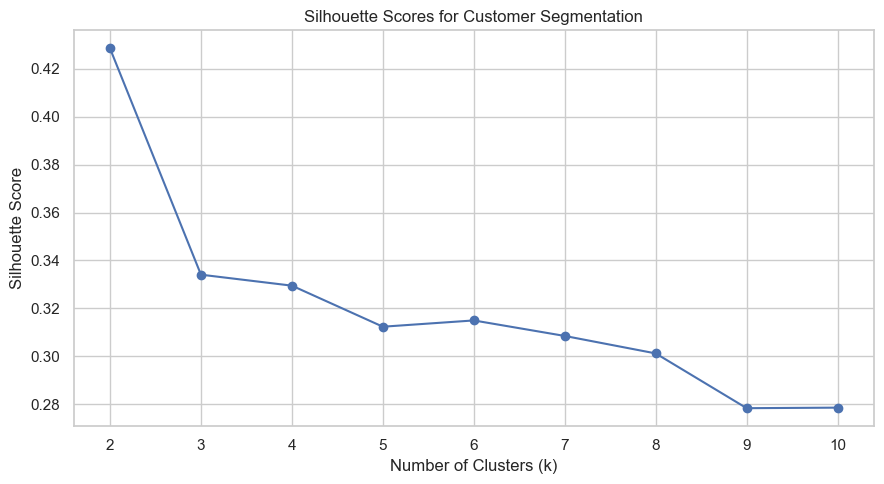


Highest sampled Silhouette Score: 2 clusters


In [8]:

# STEP 33: Evaluate K-Means using Silhouette Scores

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_results = []

# Evaluate candidate cluster counts
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        cluster_labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_results.append({
        "Clusters": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

print("SILHOUETTE SCORE RESULTS")
print("-" * 45)

display(silhouette_df.round(4))

# Visualise the results
plt.figure(figsize=(9, 5))

plt.plot(
    silhouette_df["Clusters"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Scores for Customer Segmentation")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

print(
    "\nHighest sampled Silhouette Score:",
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "Clusters"
    ],
    "clusters"
)


## 8. Apply K-Means Customer Segmentation

A four-cluster K-Means solution is provisionally selected
for further investigation.

Although two clusters achieved the highest sampled
Silhouette Score, four clusters may offer greater
business interpretability and more actionable
customer segmentation.

The final suitability of this model will be assessed
through cluster size, RFM profiles and business relevance.

In [9]:

# STEP 34: Apply four-cluster K-Means segmentation

from sklearn.cluster import KMeans

# Set provisional number of clusters
optimal_k = 4

# Initialise K-Means
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Fit model and generate cluster labels
cluster_labels = kmeans_final.fit_predict(rfm_scaled)

# Preserve original RFM values for interpretation
rfm_segmented = rfm_df.copy()

# Assign cluster labels
rfm_segmented["Cluster"] = cluster_labels

print("K-MEANS CUSTOMER SEGMENTATION")
print("-" * 50)

print(f"Total customers: {len(rfm_segmented):,}")
print(f"Number of clusters: {optimal_k}")

print("\nCustomers per cluster:")
print(
    rfm_segmented["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster distribution (%):")
print(
    (
        rfm_segmented["Cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

print("\nFirst five segmented customers:")
display(rfm_segmented.head())


K-MEANS CUSTOMER SEGMENTATION
--------------------------------------------------
Total customers: 4,337
Number of clusters: 4

Customers per cluster:
Cluster
0     704
1    1564
2    1174
3     895
Name: count, dtype: int64

Cluster distribution (%):
Cluster
0    16.23
1    36.06
2    27.07
3    20.64
Name: proportion, dtype: float64

First five segmented customers:


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,2
1,12347,3,7,4310.00,0
2,12348,76,4,1797.24,2
3,12349,19,1,1757.55,3
4,12350,311,1,334.40,1


## 9. Customer Segment Profiling

The four K-Means clusters are profiled using their original
Recency, Frequency and Monetary values.

Mean and median statistics are compared to understand
typical customer behaviour and the influence of
high-value outliers.

These profiles will inform meaningful segment names
and targeted business recommendations.

In [10]:

# STEP 35: Profile customer segments using RFM metrics

cluster_profile = (
    rfm_segmented
    .groupby("Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        MeanRecency=("Recency", "mean"),
        MedianRecency=("Recency", "median"),
        MeanFrequency=("Frequency", "mean"),
        MedianFrequency=("Frequency", "median"),
        MeanMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median"),
        TotalRevenue=("Monetary", "sum")
    )
    .reset_index()
)

# Calculate customer share
cluster_profile["CustomerSharePct"] = (
    cluster_profile["Customers"]
    / len(rfm_segmented) * 100
)

# Calculate revenue contribution
cluster_profile["RevenueSharePct"] = (
    cluster_profile["TotalRevenue"]
    / cluster_profile["TotalRevenue"].sum() * 100
)

print("CUSTOMER SEGMENT PROFILES")
print("-" * 50)

display(cluster_profile.round(2))

print("\nVALIDATION")
print("-" * 50)

print(
    "Total customers:",
    cluster_profile["Customers"].sum()
)

print(
    "Customer share:",
    round(cluster_profile["CustomerSharePct"].sum(), 2),
    "%"
)

print(
    "Revenue share:",
    round(cluster_profile["RevenueSharePct"].sum(), 2),
    "%"
)


CUSTOMER SEGMENT PROFILES
--------------------------------------------------


,Cluster,Customers,MeanRecency,MedianRecency,MeanFrequency,MedianFrequency,MeanMonetary,MedianMonetary,TotalRevenue,CustomerSharePct,RevenueSharePct
0,0,704,12.09,9.0,13.80,10.0,8118.66,3715.44,5715533.41,16.23,64.32
1,1,1564,191.44,186.0,1.36,1.0,364.08,305.19,569428.49,36.06,6.41
2,2,1174,64.38,51.0,4.22,4.0,1843.86,1379.15,2164689.40,27.07,24.36
3,3,895,22.54,20.0,1.94,2.0,488.35,414.76,437070.90,20.64,4.92



VALIDATION
--------------------------------------------------
Total customers: 4337
Customer share: 100.0 %
Revenue share: 100.0 %


## 10. Assign Customer Segment Names

The K-Means clusters are assigned descriptive names based
on their median RFM characteristics and revenue contributions.

These names provide a business-friendly interpretation of
the model outputs and support subsequent visualisation
and marketing recommendations.

In [11]:

# STEP 36: Assign descriptive customer segment names

segment_names = {
    0: "Champions",
    1: "At-Risk / Inactive",
    2: "Established Customers",
    3: "Recent Occasional Buyers"
}

# Add segment names to customer-level data
rfm_segmented["Segment"] = (
    rfm_segmented["Cluster"].map(segment_names)
)

# Add segment names to cluster profile
cluster_profile["Segment"] = (
    cluster_profile["Cluster"].map(segment_names)
)

print("CUSTOMER SEGMENT VALIDATION")
print("-" * 50)

print("\nCustomers by segment:")
print(rfm_segmented["Segment"].value_counts())

print("\nMissing segment labels:")
print(rfm_segmented["Segment"].isnull().sum())

print("\nSegment summary:")
display(
    cluster_profile[
        [
            "Segment",
            "Customers",
            "MedianRecency",
            "MedianFrequency",
            "MedianMonetary",
            "CustomerSharePct",
            "RevenueSharePct"
        ]
    ].round(2)
)

print("\nFirst five labelled customers:")
display(rfm_segmented.head())


CUSTOMER SEGMENT VALIDATION
--------------------------------------------------

Customers by segment:
Segment
At-Risk / Inactive          1564
Established Customers       1174
Recent Occasional Buyers     895
Champions                    704
Name: count, dtype: int64

Missing segment labels:
0

Segment summary:


,Segment,Customers,MedianRecency,MedianFrequency,MedianMonetary,CustomerSharePct,RevenueSharePct
0,Champions,704,9.0,10.0,3715.44,16.23,64.32
1,At-Risk / Inactive,1564,186.0,1.0,305.19,36.06,6.41
2,Established Customers,1174,51.0,4.0,1379.15,27.07,24.36
3,Recent Occasional Buyers,895,20.0,2.0,414.76,20.64,4.92



First five labelled customers:


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,2,Established Customers
1,12347,3,7,4310.00,0,Champions
2,12348,76,4,1797.24,2,Established Customers
3,12349,19,1,1757.55,3,Recent Occasional Buyers
4,12350,311,1,334.40,1,At-Risk / Inactive
